# 06 - Incident Description Analysis: NLP, LSTM/BiLSTM baseline and BERT

Security staff type a description, e.g. *"Person fell near the entrance while walking."* and the system assigns an incident category.

| Part | What it shows |
|---|---|
| 1 | Template-based train/val/test split |
| 2 | NLTK + spaCy preprocessing, word embeddings, BiLSTM baseline (TensorFlow) |
| 3 | BERT fine-tuning (PyTorch + Hugging Face) |
| 4 | Attention view, save, test with `src/incident_classification.py` |

**Honest evaluation:** the data is generated from 8 sentence templates per class. A random split would leak near-duplicate sentences into the test set. We hold out **whole templates**, so the test score measures generalisation to unseen sentence patterns.

*Needs internet on first run to download `bert-base-uncased`.*

In [1]:
# Make the project importable and use the project root as working folder
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: e:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import torch
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup, set_seed)

from src.config import *
from src.text_preprocessing import preprocess_batch

set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)
label2id = {c: i for i, c in enumerate(INCIDENT_CLASSES)}
id2label = {i: c for c, i in label2id.items()}
print("labels:", label2id)


labels: {'Facility Issue': 0, 'Fall Report': 1, 'Normal Activity': 2, 'Rapid Movement': 3}


## 1. Split by template

In [3]:
meta = pd.read_csv(INCIDENT_CSV.parent / "incidents_meta.csv")   # text, label, template_id
rng = np.random.default_rng(SEED)

val_templates, test_templates = [], []
for label, g in meta.groupby("label"):
    templates = rng.permutation(sorted(g["template_id"].unique()))
    val_templates.append(str(templates[0]))
    test_templates.append(str(templates[1]))

train_df = meta[~meta["template_id"].isin(val_templates + test_templates)].reset_index(drop=True)
val_df = meta[meta["template_id"].isin(val_templates)].reset_index(drop=True)
test_df = meta[meta["template_id"].isin(test_templates)].reset_index(drop=True)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} {len(d):5d} rows | {d['template_id'].nunique()} templates | {d['label'].value_counts().to_dict()}")

y_train = train_df["label"].map(label2id).to_numpy()
y_val = val_df["label"].map(label2id).to_numpy()
y_test = test_df["label"].map(label2id).to_numpy()

train  1157 rows | 24 templates | {'Normal Activity': 312, 'Facility Issue': 291, 'Fall Report': 278, 'Rapid Movement': 276}
val     167 rows | 4 templates | {'Rapid Movement': 54, 'Fall Report': 54, 'Facility Issue': 47, 'Normal Activity': 12}
test    212 rows | 4 templates | {'Normal Activity': 60, 'Rapid Movement': 54, 'Fall Report': 52, 'Facility Issue': 46}


## 2. Classic NLP pipeline + BiLSTM baseline

NLTK stop-words + spaCy tokenisation/lemmatisation clean the text. A trainable **word-embedding** layer maps each word to a vector, and a **BiLSTM** reads the sentence in both directions. (BERT in part 3 needs no such cleaning.)

In [4]:
raw = "Person FELL near the entrance, while walking!!"
from src.text_preprocessing import preprocess_text, preprocess_tokens
print("tokens :", preprocess_tokens(raw))
print("cleaned:", preprocess_text(raw))

train_txt = preprocess_batch(train_df["text"])
val_txt = preprocess_batch(val_df["text"])
test_txt = preprocess_batch(test_df["text"])
print(train_txt[:3])

tokens : ['person', 'fall', 'near', 'entrance', 'walk']
cleaned: person fall near entrance walk
['staff member rush beside elevator push crowd', 'guard enter building loading dock show access pass', 'visitor wait second floor colleague']


In [5]:
MAX_WORDS, SEQ_LEN = 3000, 16
vectorize = layers.TextVectorization(max_tokens=MAX_WORDS, output_sequence_length=SEQ_LEN)
vectorize.adapt(np.array(train_txt))      # vocabulary comes from TRAIN only
vocab_size = vectorize.vocabulary_size()
print("vocabulary size:", vocab_size)

def encode(texts):
    return vectorize(np.array(texts)).numpy()

Xtr, Xva, Xte = encode(train_txt), encode(val_txt), encode(test_txt)

def build_text_bilstm():
    return keras.Sequential([
        keras.Input(shape=(SEQ_LEN,)),
        layers.Embedding(vocab_size, 64, mask_zero=True),
        layers.Bidirectional(layers.LSTM(32)),
        layers.Dropout(0.3),
        layers.Dense(len(INCIDENT_CLASSES), activation="softmax"),
    ], name="text_bilstm")

baseline = build_text_bilstm()
baseline.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
baseline.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=15, batch_size=32, verbose=0,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
base_acc = accuracy_score(y_test, baseline.predict(Xte, verbose=0).argmax(axis=1))
print("BiLSTM baseline - test accuracy on unseen templates:", round(base_acc, 4))



vocabulary size: 128


BiLSTM baseline - test accuracy on unseen templates: 0.9858


## 3. BERT fine-tuning

BERT is a Transformer that uses **self-attention**: every word looks at every other word, so the meaning of "fell" depends on its context. We add a classification layer on top of pretrained `bert-base-uncased` and fine-tune everything with a small learning rate.

In [6]:
tokenizer = AutoTokenizer.from_pretrained(BERT_BASE_MODEL)
print(tokenizer.tokenize("Person fell near the entrance while walking."))

class IncidentDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, max_length=BERT_MAX_LEN)
        self.labels = [int(l) for l in labels]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

collator = DataCollatorWithPadding(tokenizer)       # pads each batch to its longest sentence
BATCH = 16
train_loader = torch.utils.data.DataLoader(IncidentDataset(train_df["text"], y_train), batch_size=BATCH, shuffle=True, collate_fn=collator)
val_loader = torch.utils.data.DataLoader(IncidentDataset(val_df["text"], y_val), batch_size=32, collate_fn=collator)
test_loader = torch.utils.data.DataLoader(IncidentDataset(test_df["text"], y_test), batch_size=32, collate_fn=collator)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

model = AutoModelForSequenceClassification.from_pretrained(
    BERT_BASE_MODEL, num_labels=len(INCIDENT_CLASSES), id2label=id2label, label2id=label2id).to(device)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

['person', 'fell', 'near', 'the', 'entrance', 'while', 'walking', '.']
device: cpu


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [7]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    losses, preds, labels = [], [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        out = model(**batch)
        losses.append(out.loss.item())
        preds.extend(out.logits.argmax(dim=-1).cpu().tolist())
        labels.extend(batch["labels"].cpu().tolist())
    return float(np.mean(losses)), accuracy_score(labels, preds), labels, preds


EPOCHS = 3
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = []
    for batch in train_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        loss = model(**batch).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
        running.append(loss.item())
    val_loss, val_acc, _, _ = evaluate(model, val_loader)
    history.append((np.mean(running), val_loss, val_acc))
    print(f"epoch {epoch}/{EPOCHS} | train loss {np.mean(running):.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")

epoch 1/3 | train loss 0.8805 | val loss 0.3476 | val acc 0.9281
epoch 2/3 | train loss 0.0521 | val loss 0.2963 | val acc 0.9281
epoch 3/3 | train loss 0.0119 | val loss 0.3037 | val acc 0.9281


## 4. Test-set evaluation (unseen templates)

BERT test accuracy: 1.0 | BiLSTM baseline: 0.9858
                 precision    recall  f1-score   support

 Facility Issue      1.000     1.000     1.000        46
    Fall Report      1.000     1.000     1.000        52
Normal Activity      1.000     1.000     1.000        60
 Rapid Movement      1.000     1.000     1.000        54

       accuracy                          1.000       212
      macro avg      1.000     1.000     1.000       212
   weighted avg      1.000     1.000     1.000       212



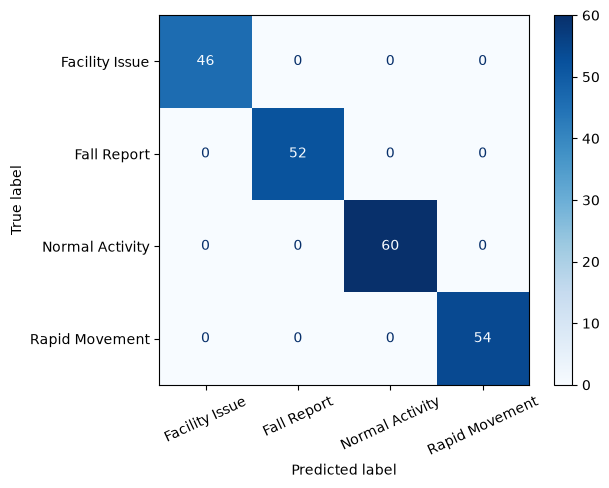

In [8]:
_, test_acc, labels, preds = evaluate(model, test_loader)
print("BERT test accuracy:", round(test_acc, 4), "| BiLSTM baseline:", round(base_acc, 4))
print(classification_report(labels, preds, labels=list(range(len(INCIDENT_CLASSES))),
                            target_names=INCIDENT_CLASSES, digits=3, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(labels, preds, labels=list(range(len(INCIDENT_CLASSES)))),
                       display_labels=INCIDENT_CLASSES).plot(cmap="Blues", xticks_rotation=25)
plt.show()

## 5. Save the fine-tuned model

In [9]:
BERT_MODEL_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(BERT_MODEL_DIR)
tokenizer.save_pretrained(BERT_MODEL_DIR)
print("Saved to:", BERT_MODEL_DIR)
print(sorted(p.name for p in BERT_MODEL_DIR.iterdir()))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: E:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project\models\bert_incident
['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


## 6. Attention view (optional)
How much the `[CLS]` token (the sentence summary used for classification) attends to each word in the last layer, averaged over heads.

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

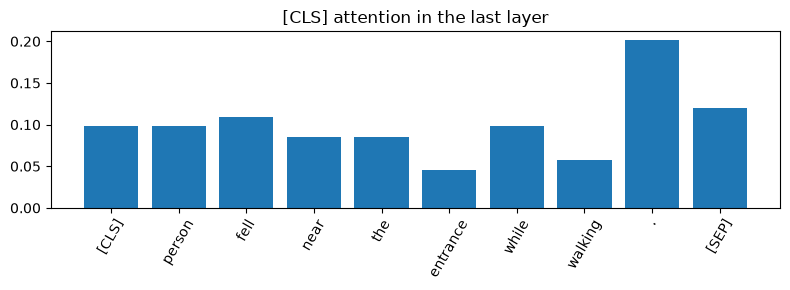

In [10]:
try:
    eager = AutoModelForSequenceClassification.from_pretrained(
        BERT_MODEL_DIR, attn_implementation="eager", output_attentions=True).eval()
    sentence = "Person fell near the entrance while walking."
    enc = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        att = eager(**enc).attentions[-1][0].mean(dim=0)          # (tokens, tokens)
    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    plt.figure(figsize=(8, 3))
    plt.bar(range(len(tokens)), att[0].numpy())
    plt.xticks(range(len(tokens)), tokens, rotation=60)
    plt.title("[CLS] attention in the last layer")
    plt.tight_layout(); plt.show()
except Exception as exc:
    print("Attention view skipped:", exc)

## 7. Test with the project's inference code

In [11]:
from src.incident_classification import predict_incident

examples = [
    "Person fell near the entrance while walking.",
    "A visitor ran quickly through the corridor.",
    "The elevator door is broken and the light is flickering.",
    "Everything looked normal during the evening patrol.",
]
for text in examples:
    r = predict_incident(text)
    print(f"{r['label']:16s} {r['confidence']:.2f} | {text}")
print()
print(r["summary"])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Fall Report      0.99 | Person fell near the entrance while walking.
Rapid Movement   0.99 | A visitor ran quickly through the corridor.
Facility Issue   0.99 | The elevator door is broken and the light is flickering.
Normal Activity  0.57 | Everything looked normal during the evening patrol.

Incident classified as 'Normal Activity' with 57.1% confidence. Report: "Everything looked normal during the evening patrol."


**Done:** `models/bert_incident/` is saved. Next: notebook 07 (ANN).